In [ ]:
import os, sys, json, time, math, random, glob, shutil, zipfile, platform, subprocess, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import sklearn
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             adjusted_rand_score as ARI, normalized_mutual_info_score as NMI)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = DEVICE == 'cuda'
print('Python', platform.python_version(), '| torch', torch.__version__, '| numpy', np.__version__,
      '| pandas', pd.__version__, '| sklearn', sklearn.__version__)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
if DEVICE == 'cpu':
    print('PERINGATAN: GPU tidak aktif. Aktifkan Runtime > Change runtime type > GPU.')
OUT_DIR = '/content/outputs'
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option('display.precision', 4)

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
Device: cuda Tesla T4


In [ ]:
from google.colab import files

DATA_DIR = '/content/data'
NEEDED = ['clustering.npz', 'clustering_meta.csv']
os.makedirs(DATA_DIR, exist_ok=True)

def _rapikan_upload():
    for f in NEEDED:
        tujuan = os.path.join(DATA_DIR, f)
        if os.path.exists(f) and not os.path.exists(tujuan):
            shutil.move(f, tujuan)
    for zp in glob.glob('*.zip'):
        with zipfile.ZipFile(zp) as z:
            for f in NEEDED:
                if f in z.namelist() and not os.path.exists(os.path.join(DATA_DIR, f)):
                    z.extract(f, DATA_DIR)

def _kurang():
    return [f for f in NEEDED if not os.path.exists(os.path.join(DATA_DIR, f))]

_rapikan_upload()
if _kurang():
    print('Silakan upload file berikut:', _kurang())
    uploaded = files.upload()
    _rapikan_upload()
assert not _kurang(), f'Masih kurang: {_kurang()} -> jalankan sel ini lagi dan upload file tersebut'
for f in NEEDED:
    print(f'{f:22s} {os.path.getsize(os.path.join(DATA_DIR, f))/1e6:7.1f} MB')

clustering.npz           130.3 MB
clustering_meta.csv        0.6 MB


In [ ]:
QUICK = False

CFG = dict(
    epochs     = 3 if QUICK else 30,
    batch      = 512,
    lr         = 1e-3,
    wd         = 1e-4,
    tau        = 0.2,
    tau_cross  = 0.1,
    lam_cross  = 1.0,
    max_shift  = 4,
    scale_rng  = 1.25,
)
K_RANGE   = list(range(4, 21))
K_OVERRIDE = None
PCA_DIM   = 32
SEED = 42

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
set_seed(SEED)
print(CFG)

{'epochs': 30, 'batch': 512, 'lr': 0.001, 'wd': 0.0001, 'tau': 0.2, 'tau_cross': 0.1, 'lam_cross': 1.0, 'max_shift': 4, 'scale_rng': 1.25}


In [ ]:
meta = pd.read_csv(f'{DATA_DIR}/clustering_meta.csv')
_d = np.load(f'{DATA_DIR}/clustering.npz')
IMG = _d['gambar']
SPEC_RAW = _d['spektrum'].astype(np.float32)
assert (meta['indeks'].values == np.arange(len(meta))).all()
MIC = (meta['mikroskop'] == 'M2').astype(int).values
N = len(meta)
print('gambar', IMG.shape, '| spektrum', SPEC_RAW.shape, '| NaN spektrum:', int(np.isnan(SPEC_RAW).sum()))
print('mikroskop:', meta['mikroskop'].value_counts().to_dict())
meta.head()

gambar (36000, 64, 64) | spektrum (36000, 128) | NaN spektrum: 0
mikroskop: {'M1': 21636, 'M2': 14364}


,indeks,id_sampel,mikroskop
0,0,S966119,M1
1,1,S315633,M2
2,2,S805122,M1
3,3,S467543,M1
4,4,S475842,M1


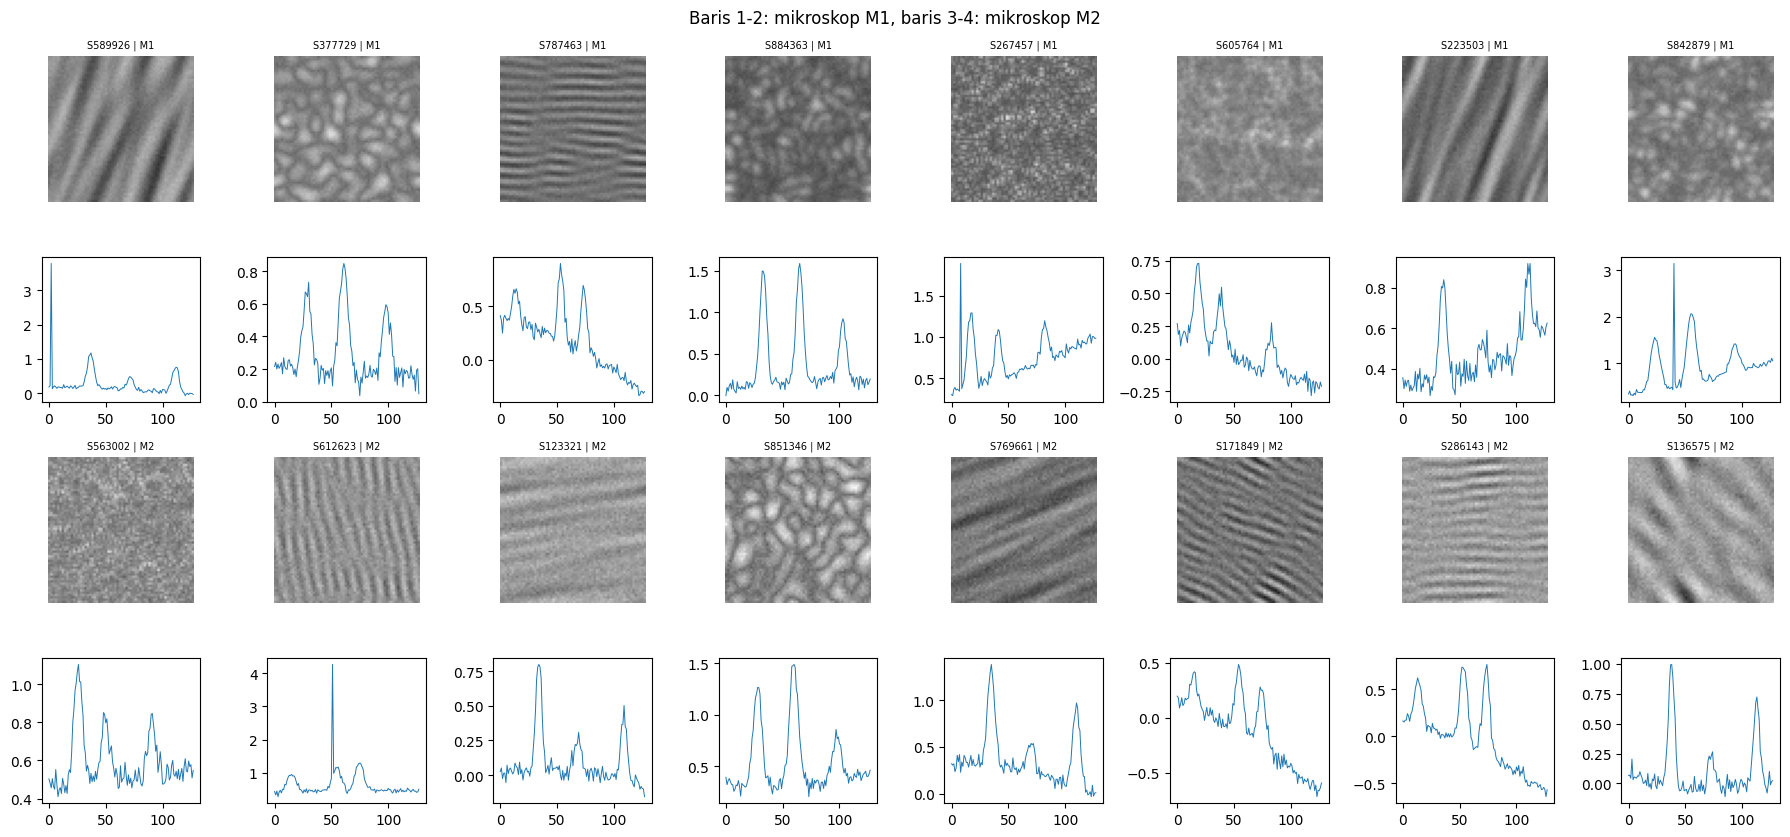

In [ ]:
rng = np.random.default_rng(0)
ex = np.concatenate([rng.choice(np.where(MIC == 0)[0], 8, replace=False), rng.choice(np.where(MIC == 1)[0], 8, replace=False)])
fig, ax = plt.subplots(4, 8, figsize=(18, 8.5))
for j, k in enumerate(ex):
    r, c = (j // 8) * 2, j % 8
    ax[r, c].imshow(IMG[k], cmap='gray', vmin=0, vmax=255); ax[r, c].axis('off'); ax[r, c].set_title(f'{meta.id_sampel[k]} | {meta.mikroskop[k]}', fontsize=7)
    ax[r + 1, c].plot(SPEC_RAW[k], lw=.7)
plt.suptitle('Baris 1-2: mikroskop M1, baris 3-4: mikroskop M2'); plt.tight_layout(); plt.show()

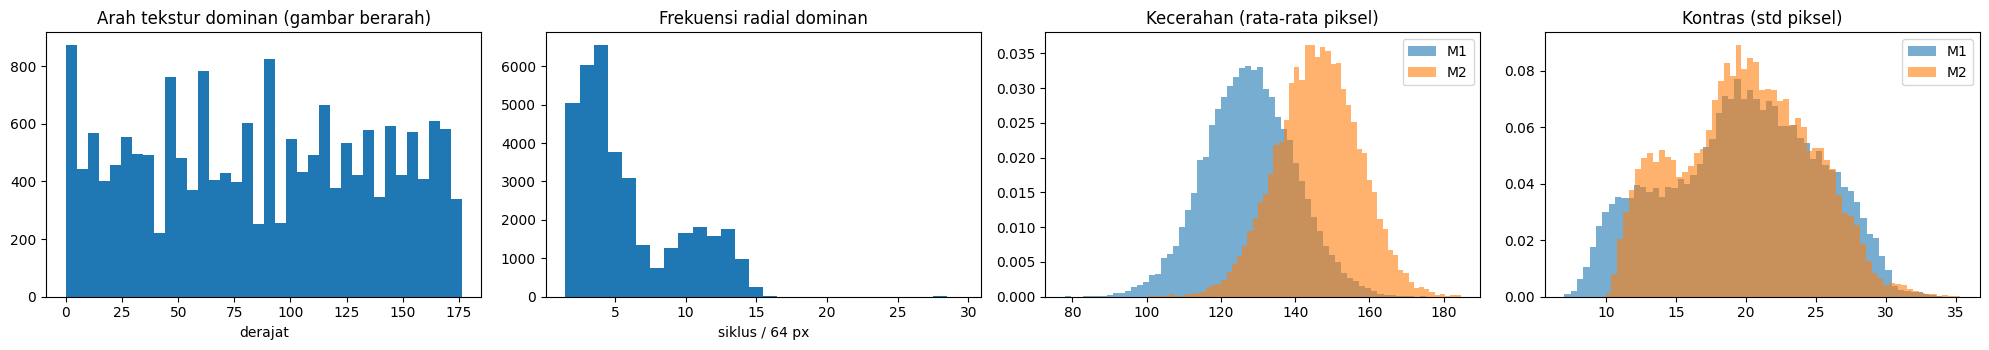

    kecerahan  kontras  frek. dominan
M1     127.80     19.7           6.08
M2     146.07     19.9           6.07


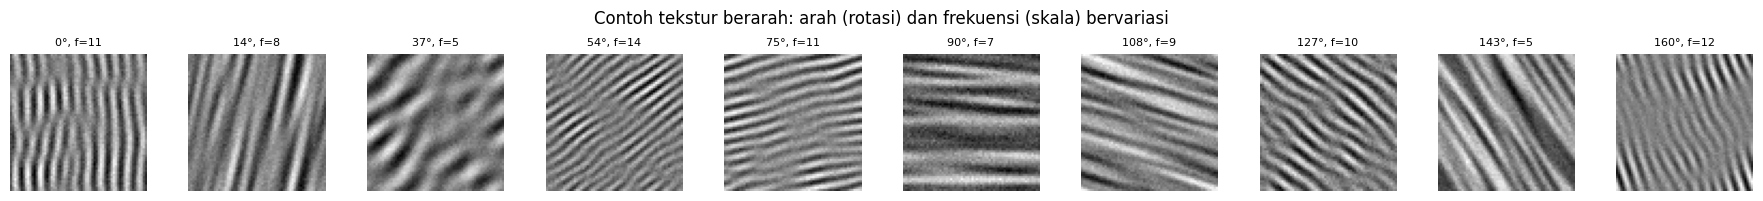

In [ ]:
def fft_stats(imgs, chunk=2000):
    yy, xx = np.mgrid[-32:32, -32:32]
    r = np.sqrt(xx ** 2 + yy ** 2); ang = np.arctan2(yy, xx)
    band = (r > 2) & (r < 30)
    rad_bins = np.clip(r.astype(int), 0, 31)
    orient, freq, aniso, radial = [], [], [], []
    for i in range(0, len(imgs), chunk):
        g = imgs[i:i + chunk].astype(np.float32)
        g = (g - g.mean((1, 2), keepdims=True)) / (g.std((1, 2), keepdims=True) + 1e-6)
        P = np.abs(np.fft.fftshift(np.fft.fft2(g), axes=(1, 2))).astype(np.float32) ** 2
        Pb = P[:, band]
        k = Pb.argmax(1)
        orient.append(np.degrees(ang[band][k]) % 180); freq.append(r[band][k])
        abins = ((ang[band] % np.pi) / np.pi * 12).astype(int) % 12
        E = np.stack([Pb[:, abins == a].mean(1) for a in range(12)], 1)
        aniso.append(np.log(E.max(1) / (E.min(1) + 1e-9)))
        radial.append(np.stack([P[:, rad_bins == q].mean(1) for q in range(1, 32)], 1))
    return np.concatenate(orient), np.concatenate(freq), np.concatenate(aniso), np.log(np.concatenate(radial) + 1e-6)

ORIENT, FREQ, ANISO, RADIAL = fft_stats(IMG)
img_mean = np.concatenate([IMG[i:i + 4000].reshape(-1, 4096).mean(1) for i in range(0, N, 4000)])
img_std = np.concatenate([IMG[i:i + 4000].reshape(-1, 4096).astype(np.float32).std(1) for i in range(0, N, 4000)])

fig, ax = plt.subplots(1, 4, figsize=(20, 3.6))
strong = ANISO > np.percentile(ANISO, 50)
ax[0].hist(ORIENT[strong], bins=36); ax[0].set_title('Arah tekstur dominan (gambar berarah)'); ax[0].set_xlabel('derajat')
ax[1].hist(FREQ, bins=np.arange(2, 31) - .5); ax[1].set_title('Frekuensi radial dominan'); ax[1].set_xlabel('siklus / 64 px')
for k, nm in [(0, 'M1'), (1, 'M2')]:
    ax[2].hist(img_mean[MIC == k], bins=60, alpha=.6, density=True, label=nm)
    ax[3].hist(img_std[MIC == k], bins=60, alpha=.6, density=True, label=nm)
ax[2].set_title('Kecerahan (rata-rata piksel)'); ax[2].legend(); ax[3].set_title('Kontras (std piksel)'); ax[3].legend()
plt.tight_layout(); plt.show()

print(pd.DataFrame({'kecerahan': [img_mean[MIC == 0].mean(), img_mean[MIC == 1].mean()],
                    'kontras': [img_std[MIC == 0].mean(), img_std[MIC == 1].mean()],
                    'frek. dominan': [FREQ[MIC == 0].mean(), FREQ[MIC == 1].mean()]}, index=['M1', 'M2']).round(2))

idx = np.where(ANISO > np.percentile(ANISO, 90))[0][:400]
idx = idx[np.argsort(ORIENT[idx])][::40][:10]
fig, ax = plt.subplots(1, 10, figsize=(18, 2))
for a, k in zip(ax, idx):
    a.imshow(IMG[k], cmap='gray'); a.axis('off'); a.set_title(f'{ORIENT[k]:.0f}°, f={FREQ[k]:.0f}', fontsize=8)
plt.suptitle('Contoh tekstur berarah: arah (rotasi) dan frekuensi (skala) bervariasi'); plt.tight_layout(); plt.show()

### a.3 Distorsi spektrum: pergeseran, baseline, spike

Sampel dengan spike: 22.47% | titik spike: 0.204%


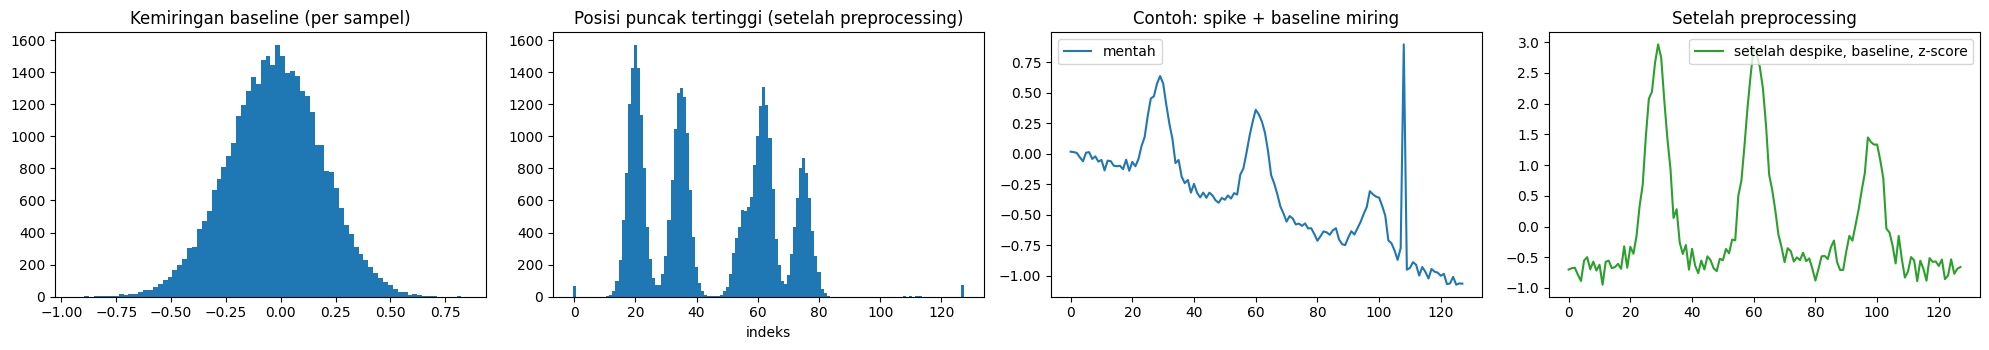

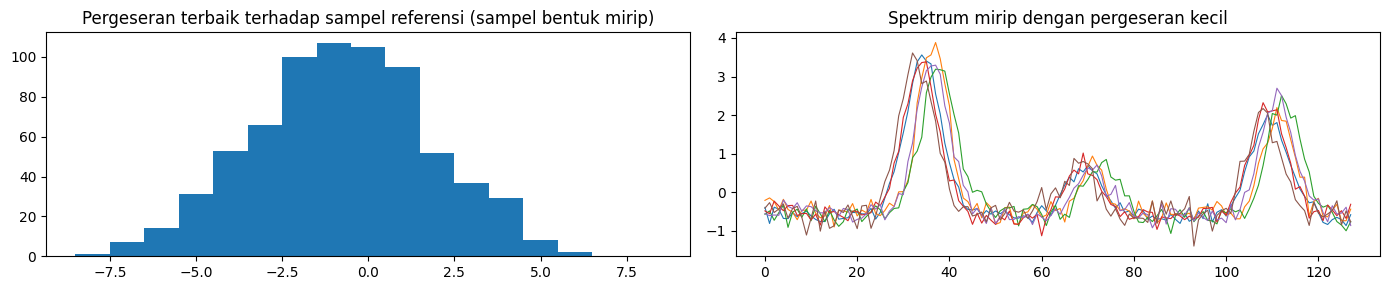

Mikroskop vs spektrum (seharusnya tidak terkait): beda rata-rata kemiringan baseline M1/M2 = 0.0019


In [ ]:
def despike(x, k=5, thr=20.0):
    pad = np.pad(x, ((0, 0), (k // 2, k // 2)), mode='edge')
    med = np.median(np.lib.stride_tricks.sliding_window_view(pad, k, axis=1), axis=-1)
    res = x - med
    sig = np.median(np.abs(res)) * 1.4826 + 1e-6
    spike = np.abs(res) > thr * sig
    return np.where(spike, med, x), spike

def remove_baseline(x, n_iter=6):
    t = np.linspace(-1, 1, x.shape[1], dtype=np.float32)
    w = np.ones_like(x)
    for _ in range(n_iter):
        sw, st, stt = w.sum(1), (w * t).sum(1), (w * t * t).sum(1)
        sx, stx = (w * x).sum(1), (w * t * x).sum(1)
        det = sw * stt - st ** 2 + 1e-9
        b = (sw * stx - st * sx) / det; a = (sx - b * st) / sw
        base = a[:, None] + b[:, None] * t[None, :]
        w_new = (x <= base).astype(np.float32)
        w = np.where(w_new.sum(1, keepdims=True) >= 10, w_new, 1.0)
    return x - base, a, b

def preprocess_spec(x):
    x1, spike = despike(x)
    x2, a, b = remove_baseline(x1)
    x3 = (x2 - x2.mean(1, keepdims=True)) / (x2.std(1, keepdims=True) + 1e-6)
    return x3.astype(np.float32), spike, a, b

SPEC, SPIKE, BASE_A, BASE_B = preprocess_spec(SPEC_RAW)
PEAK = SPEC.argmax(1)
print(f'Sampel dengan spike: {SPIKE.any(1).mean():.2%} | titik spike: {SPIKE.mean():.3%}')

fig, ax = plt.subplots(1, 4, figsize=(20, 3.6))
ax[0].hist(BASE_B, bins=80); ax[0].set_title('Kemiringan baseline (per sampel)')
ax[1].hist(PEAK, bins=np.arange(129) - .5); ax[1].set_title('Posisi puncak tertinggi (setelah preprocessing)'); ax[1].set_xlabel('indeks')
_c = np.where(SPIKE.any(1) & (np.abs(BASE_B) > np.percentile(np.abs(BASE_B), 80)))[0]
k = _c[0] if len(_c) else int(np.argmax(np.abs(BASE_B)))
ax[2].plot(SPEC_RAW[k], label='mentah'); ax[2].set_title('Contoh: spike + baseline miring'); ax[2].legend()
ax[3].plot(SPEC[k], color='tab:green', label='setelah despike, baseline, z-score'); ax[3].legend(); ax[3].set_title('Setelah preprocessing')
plt.tight_layout(); plt.show()

ref = SPEC[0]
cc = np.stack([np.roll(SPEC[:3000], s, axis=1) @ ref for s in range(-8, 9)], 1)
best = cc.argmax(1) - 8; good = cc.max(1) > 0.85 * (ref @ ref)
plt.figure(figsize=(14, 3))
plt.subplot(1, 2, 1); plt.hist(best[good], bins=np.arange(-8, 10) - .5); plt.title('Pergeseran terbaik terhadap sampel referensi (sampel bentuk mirip)')
plt.subplot(1, 2, 2)
for kk in np.where(good)[0][:6]: plt.plot(SPEC[kk], lw=.8)
plt.title('Spektrum mirip dengan pergeseran kecil'); plt.tight_layout(); plt.show()
print('Mikroskop vs spektrum (seharusnya tidak terkait): beda rata-rata kemiringan baseline M1/M2 =',
      round(float(BASE_B[MIC == 0].mean() - BASE_B[MIC == 1].mean()), 4))

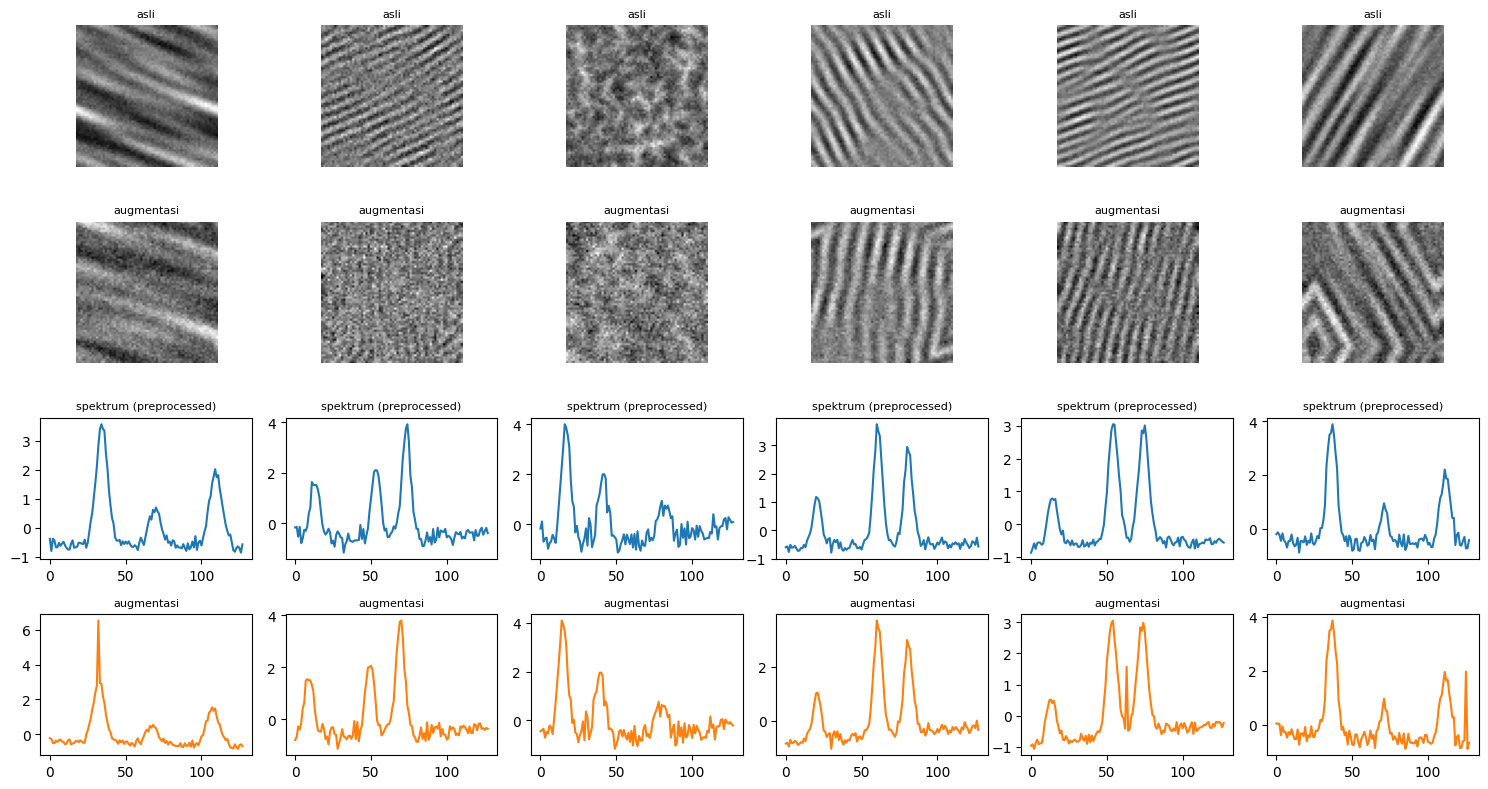

In [ ]:
IMG_T  = torch.from_numpy(IMG).to(DEVICE).half().div_(255.0).unsqueeze(1)
SPEC_T = torch.from_numpy(SPEC).to(DEVICE).half()
T_LIN  = torch.linspace(-1, 1, 128, device=DEVICE)
T_IDX  = torch.arange(128, device=DEVICE)

def std_img(x):
    return (x - x.mean((2, 3), keepdim=True)) / (x.std((2, 3), keepdim=True) + 1e-5)

def aug_img(x, cfg=CFG):
    B, dev = x.shape[0], x.device
    ang = torch.rand(B, device=dev) * 2 * math.pi
    sc = torch.exp((torch.rand(B, device=dev) * 2 - 1) * math.log(cfg['scale_rng']))
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    tx, ty = (torch.rand(B, device=dev) * 2 - 1) * 0.1, (torch.rand(B, device=dev) * 2 - 1) * 0.1
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False), padding_mode='reflection', align_corners=False)
    x = torch.where((torch.rand(B, device=dev) < .5)[:, None, None, None], x.flip(3), x)
    gamma = torch.exp((torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * math.log(1.5))
    x = x.clamp(1e-4, 1) ** gamma
    x = x * (0.7 + 0.6 * torch.rand(B, 1, 1, 1, device=dev)) + (torch.rand(B, 1, 1, 1, device=dev) - .5) * 0.3
    xb = F.avg_pool2d(F.pad(x, (1, 1, 1, 1), mode='reflect'), 3, 1)
    x = torch.where((torch.rand(B, device=dev) < .3)[:, None, None, None], xb, x)
    x = x + 0.03 * torch.randn_like(x)
    return std_img(x)

def aug_spec(x, cfg=CFG):
    B, dev = x.shape[0], x.device
    sh = torch.randint(-cfg['max_shift'], cfg['max_shift'] + 1, (B, 1), device=dev)
    x = torch.gather(x, 1, (T_IDX[None, :] - sh).clamp(0, 127))
    x = x * (0.8 + 0.4 * torch.rand(B, 1, device=dev))
    x = x + (torch.rand(B, 1, device=dev) * 2 - 1) * 0.5 * T_LIN[None] + (torch.rand(B, 1, device=dev) - .5) * 0.6
    sp = torch.rand(B, device=dev) < 0.3
    rows = torch.arange(B, device=dev)[sp]
    x[rows, torch.randint(0, 128, (int(sp.sum()),), device=dev)] += 1 + 3 * torch.rand(int(sp.sum()), device=dev)
    x = x + 0.05 * torch.randn_like(x)
    return (x - x.mean(1, keepdim=True)) / (x.std(1, keepdim=True) + 1e-5)

with torch.no_grad():
    k = torch.arange(6, device=DEVICE)
    xi = IMG_T[k].float(); xs = SPEC_T[k].float()
    fig, ax = plt.subplots(4, 6, figsize=(15, 8))
    for j in range(6):
        ax[0, j].imshow(std_img(xi[j:j+1])[0, 0].cpu(), cmap='gray'); ax[0, j].axis('off'); ax[0, j].set_title('asli', fontsize=8)
        ax[1, j].imshow(aug_img(xi[j:j+1])[0, 0].cpu(), cmap='gray'); ax[1, j].axis('off'); ax[1, j].set_title('augmentasi', fontsize=8)
        ax[2, j].plot(xs[j].cpu()); ax[2, j].set_title('spektrum (preprocessed)', fontsize=8)
        ax[3, j].plot(aug_spec(xs[j:j+1])[0].cpu(), color='tab:orange'); ax[3, j].set_title('augmentasi', fontsize=8)
    plt.tight_layout(); plt.show()

In [ ]:
def cbr2(i, o): return [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]
def cbr1(i, o, k): return [nn.Conv1d(i, o, k, padding=k // 2, bias=False), nn.BatchNorm1d(o), nn.ReLU(inplace=True)]

class ImgEnc(nn.Module):
    def __init__(self, w=32):
        super().__init__()
        self.net = nn.Sequential(
            *cbr2(1, w), nn.MaxPool2d(2),
            *cbr2(w, 2 * w), *cbr2(2 * w, 2 * w), nn.MaxPool2d(2),
            *cbr2(2 * w, 4 * w), *cbr2(4 * w, 4 * w), nn.MaxPool2d(2),
            *cbr2(4 * w, 8 * w), *cbr2(8 * w, 8 * w), nn.AdaptiveAvgPool2d(1), nn.Flatten())
    def forward(self, x): return self.net(x)

class SpecEnc(nn.Module):
    def __init__(self, w=64):
        super().__init__()
        self.net = nn.Sequential(
            *cbr1(1, w, 7), *cbr1(w, w, 5), nn.MaxPool1d(2),
            *cbr1(w, 2 * w, 5), *cbr1(2 * w, 2 * w, 3), nn.MaxPool1d(2),
            *cbr1(2 * w, 4 * w, 3), *cbr1(4 * w, 4 * w, 3))
        self.fc = nn.Linear(8 * w, 256)
    def forward(self, x):
        h = self.net(x[:, None, :])
        return self.fc(torch.cat([h.mean(-1), h.amax(-1)], 1))

def proj(i=256, o=128): return nn.Sequential(nn.Linear(i, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True), nn.Linear(256, o))

class CLModel(nn.Module):
    def __init__(self, use_img, use_spec, cross):
        super().__init__()
        self.use_img, self.use_spec, self.cross = use_img, use_spec, cross
        if use_img: self.ie, self.pi = ImgEnc(), proj()
        if use_spec: self.se, self.ps = SpecEnc(), proj()
        if cross: self.ci, self.cs = proj(), proj()

def nt_xent(z1, z2, tau):
    with torch.autocast('cuda', enabled=False):
        z = F.normalize(torch.cat([z1, z2]).float(), dim=1)
        B = z1.shape[0]
        sim = z @ z.t() / tau
        sim = sim.masked_fill(torch.eye(2 * B, dtype=torch.bool, device=z.device), float('-inf'))
        tgt = torch.cat([torch.arange(B, 2 * B), torch.arange(0, B)]).to(z.device)
        return F.cross_entropy(sim, tgt)

def clip_loss(a, b, tau):
    with torch.autocast('cuda', enabled=False):
        a, b = F.normalize(a.float(), dim=1), F.normalize(b.float(), dim=1)
        logits = a @ b.t() / tau
        t = torch.arange(len(a), device=a.device)
        return (F.cross_entropy(logits, t) + F.cross_entropy(logits.t(), t)) / 2

for nm, (ui, us, cr) in {'gambar': (1, 0, 0), 'spektrum': (0, 1, 0), 'joint': (1, 1, 1)}.items():
    print(f'{nm:9s} params: {sum(p.numel() for p in CLModel(ui, us, cr).parameters())/1e6:.2f} M')

gambar    params: 1.26 M
spektrum  params: 0.64 M
joint     params: 2.10 M


In [ ]:
def train_cl(use_img, use_spec, cross, seed=0, cfg=CFG, tag=''):
    set_seed(seed)
    model = CLModel(use_img, use_spec, cross).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    spe = N // cfg['batch']
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg['lr'], total_steps=cfg['epochs'] * spe, pct_start=0.1)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    gen = torch.Generator().manual_seed(seed)
    hist, t0 = [], time.time()
    for ep in range(cfg['epochs']):
        model.train(); perm = torch.randperm(N, generator=gen)
        acc = {'total': 0.0, 'img': 0.0, 'spec': 0.0, 'cross': 0.0}
        for s in range(spe):
            b = perm[s * cfg['batch']:(s + 1) * cfg['batch']].to(DEVICE)
            with torch.no_grad():
                if use_img:  xi = IMG_T[b].float(); i1, i2 = aug_img(xi), aug_img(xi)
                if use_spec: xs = SPEC_T[b].float(); s1, s2 = aug_spec(xs), aug_spec(xs)
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                loss = 0.0
                if use_img:
                    hi1, hi2 = model.ie(i1), model.ie(i2)
                    li = nt_xent(model.pi(hi1), model.pi(hi2), cfg['tau']); loss = loss + li; acc['img'] += li.item()
                if use_spec:
                    hs1, hs2 = model.se(s1), model.se(s2)
                    ls = nt_xent(model.ps(hs1), model.ps(hs2), cfg['tau']); loss = loss + ls; acc['spec'] += ls.item()
                if cross:
                    lc = clip_loss(model.ci(hi1), model.cs(hs1), cfg['tau_cross']); loss = loss + cfg['lam_cross'] * lc; acc['cross'] += lc.item()
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            acc['total'] += loss.item()
        h = {'epoch': ep + 1, **{k: v / spe for k, v in acc.items()}}
        hist.append(h)
        if ep == 0 or (ep + 1) % 5 == 0 or ep + 1 == cfg['epochs']:
            print(f"  [{tag}] ep {ep+1:2d}/{cfg['epochs']} " + ' '.join(f'{k}={v:.3f}' for k, v in h.items() if k != 'epoch' and v != 0)
                  + f' ({time.time()-t0:.0f}s)')
    return model, pd.DataFrame(hist)

@torch.no_grad()
def embed(model, bs=2048):
    model.eval(); outs = {'img': [], 'spec': []}
    for i in range(0, N, bs):
        b = torch.arange(i, min(i + bs, N), device=DEVICE)
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            if model.use_img:  outs['img'].append(F.normalize(model.ie(std_img(IMG_T[b].float())).float(), dim=1).cpu())
            if model.use_spec: outs['spec'].append(F.normalize(model.se(SPEC_T[b].float()).float(), dim=1).cpu())
    return {k: torch.cat(v).numpy() for k, v in outs.items() if v}

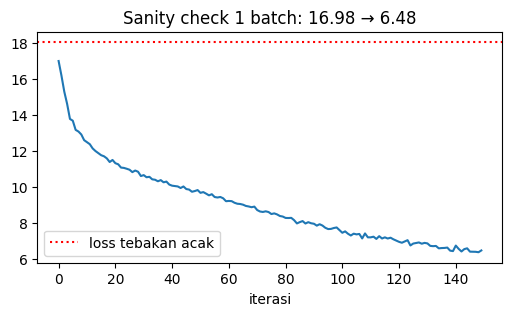

In [ ]:
set_seed(0)
m = CLModel(1, 1, 1).to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
b = torch.arange(256, device=DEVICE); xi, xs = IMG_T[b].float(), SPEC_T[b].float()
ls_ = []
for it in range(150):
    m.train()
    with torch.no_grad(): i1, i2, s1, s2 = aug_img(xi), aug_img(xi), aug_spec(xs), aug_spec(xs)
    hi1, hs1 = m.ie(i1), m.se(s1)
    loss = nt_xent(m.pi(hi1), m.pi(m.ie(i2)), .2) + nt_xent(m.ps(hs1), m.ps(m.se(s2)), .2) + clip_loss(m.ci(hi1), m.cs(hs1), .1)
    opt.zero_grad(); loss.backward(); opt.step(); ls_.append(loss.item())
plt.figure(figsize=(6, 3)); plt.plot(ls_); plt.axhline(2 * math.log(511) + math.log(256), color='r', ls=':', label='loss tebakan acak')
plt.title(f'Sanity check 1 batch: {ls_[0]:.2f} → {ls_[-1]:.2f}'); plt.legend(); plt.xlabel('iterasi'); plt.show()
del m

  [gambar] ep  1/30 total=5.107 img=5.107 (11s)
  [gambar] ep  5/30 total=3.565 img=3.565 (55s)
  [gambar] ep 10/30 total=3.351 img=3.351 (110s)
  [gambar] ep 15/30 total=3.249 img=3.249 (167s)
  [gambar] ep 20/30 total=3.180 img=3.180 (224s)
  [gambar] ep 25/30 total=3.134 img=3.134 (281s)
  [gambar] ep 30/30 total=3.121 img=3.121 (338s)
  [spektrum] ep  1/30 total=4.940 spec=4.940 (2s)
  [spektrum] ep  5/30 total=2.585 spec=2.585 (10s)
  [spektrum] ep 10/30 total=2.500 spec=2.500 (20s)
  [spektrum] ep 15/30 total=2.461 spec=2.461 (30s)
  [spektrum] ep 20/30 total=2.434 spec=2.434 (40s)
  [spektrum] ep 25/30 total=2.417 spec=2.417 (50s)
  [spektrum] ep 30/30 total=2.411 spec=2.411 (60s)
  [joint] ep  1/30 total=15.623 img=5.216 spec=4.936 cross=5.470 (14s)
  [joint] ep  5/30 total=11.060 img=3.599 spec=2.592 cross=4.869 (68s)
  [joint] ep 10/30 total=10.723 img=3.362 spec=2.501 cross=4.860 (136s)
  [joint] ep 15/30 total=10.576 img=3.258 spec=2.464 cross=4.854 (204s)
  [joint] ep 20/3

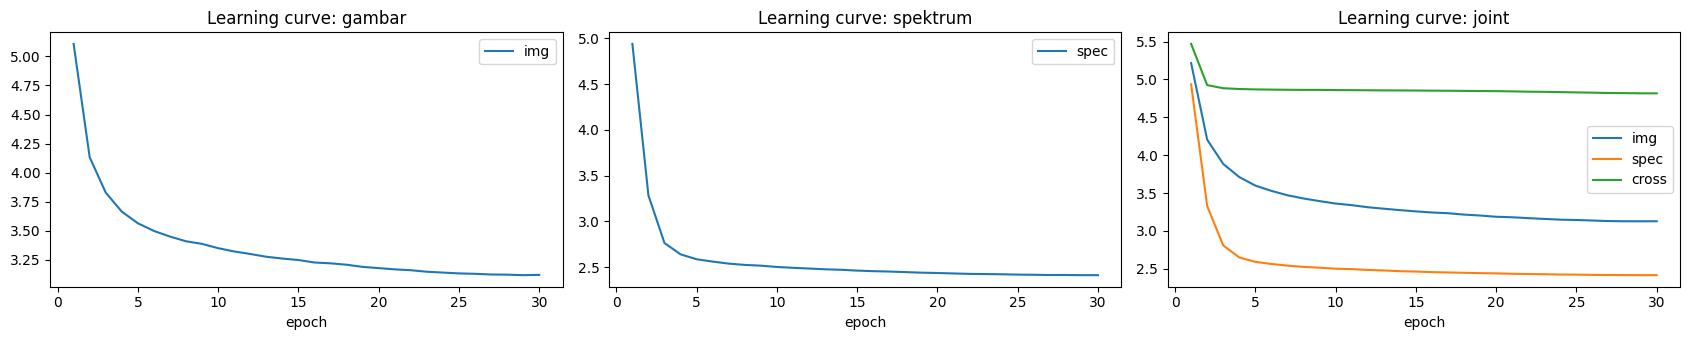

{'gambar saja': (36000, 32), 'spektrum saja': (36000, 32), 'late (concat 2 model)': (36000, 32), 'joint (SimCLR + CLIP)': (36000, 32), 'fitur tangan (baseline)': (36000, 32)}


In [ ]:
MODELS, HISTS = {}, {}
for tag, args in [('gambar', (True, False, False)), ('spektrum', (False, True, False)), ('joint', (True, True, True))]:
    MODELS[tag], HISTS[tag] = train_cl(*args, seed=0, tag=tag)
    torch.save(MODELS[tag].state_dict(), f'{OUT_DIR}/simclr_{tag}.pt')

fig, ax = plt.subplots(1, 3, figsize=(17, 3.5))
for a, tag in zip(ax, HISTS):
    h = HISTS[tag]
    for c in ['img', 'spec', 'cross']:
        if h[c].abs().sum() > 0: a.plot(h.epoch, h[c], label=c)
    a.set_title(f'Learning curve: {tag}'); a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.show()

E_img  = embed(MODELS['gambar'])['img']
E_spec = embed(MODELS['spektrum'])['spec']
_ej = embed(MODELS['joint'])
EMB = {
    'gambar saja':              E_img,
    'spektrum saja':            E_spec,
    'late (concat 2 model)':    np.concatenate([E_img, E_spec], 1) / np.sqrt(2),
    'joint (SimCLR + CLIP)':    np.concatenate([_ej['img'], _ej['spec']], 1) / np.sqrt(2),
}
_hand = np.concatenate([SPEC, (RADIAL - RADIAL.mean(1, keepdims=True)), ANISO[:, None]], 1)
EMB['fitur tangan (baseline)'] = (_hand - _hand.mean(0)) / (_hand.std(0) + 1e-6)

def reduce(E, d=PCA_DIM, seed=SEED):
    Z = PCA(min(d, E.shape[1]), random_state=seed).fit_transform(E)
    return (Z / Z.std()).astype(np.float32)
Z = {k: reduce(v) for k, v in EMB.items()}
print({k: v.shape for k, v in Z.items()})

  K= 4 sil=0.382 DB=1.192 BIC=179030 stab=1.000 (2s)
  K= 5 sil=0.437 DB=1.046 BIC=107970 stab=1.000 (2s)
  K= 6 sil=0.464 DB=0.902 BIC=88015 stab=1.000 (2s)
  K= 7 sil=0.389 DB=1.315 BIC=47831 stab=0.917 (2s)
  K= 8 sil=0.299 DB=1.649 BIC=44496 stab=0.857 (6s)
  K= 9 sil=0.296 DB=1.656 BIC=41579 stab=0.879 (4s)
  K=10 sil=0.225 DB=2.266 BIC=40101 stab=0.792 (6s)
  K=11 sil=0.169 DB=2.347 BIC=41636 stab=0.749 (6s)
  K=12 sil=0.168 DB=2.204 BIC=26385 stab=0.780 (6s)
  K=13 sil=0.167 DB=2.348 BIC=24306 stab=0.763 (7s)
  K=14 sil=0.131 DB=2.394 BIC=27354 stab=0.704 (5s)
  K=15 sil=0.164 DB=2.422 BIC=26522 stab=0.733 (9s)
  K=16 sil=0.164 DB=2.361 BIC=27726 stab=0.695 (9s)
  K=17 sil=0.123 DB=2.435 BIC=31178 stab=0.695 (7s)
  K=18 sil=0.120 DB=2.369 BIC=32815 stab=0.680 (8s)
  K=19 sil=0.114 DB=2.346 BIC=34357 stab=0.715 (9s)
  K=20 sil=0.114 DB=2.419 BIC=34820 stab=0.654 (11s)
K terbaik per kriteria: {'silhouette': 16, 'BIC': 13, 'stabilitas': 9} | (Davies-Bouldin minimum, sebagai pemband

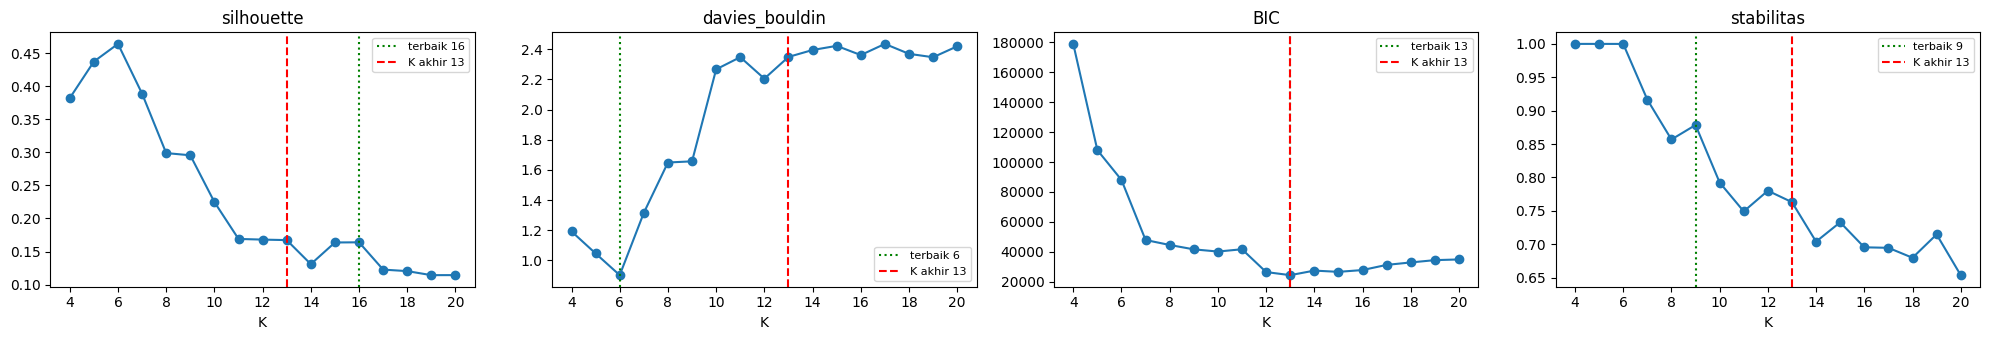

In [ ]:
def stability(Zx, k, n_rep=3, seed=0):
    r = np.random.default_rng(seed); out = []
    for i in range(n_rep):
        a = r.choice(len(Zx), len(Zx) // 2, replace=False); b = r.choice(len(Zx), len(Zx) // 2, replace=False)
        la = KMeans(k, n_init=3, random_state=i).fit(Zx[a]).predict(Zx)
        lb = KMeans(k, n_init=3, random_state=100 + i).fit(Zx[b]).predict(Zx)
        out.append(ARI(la, lb))
    return float(np.mean(out))

def k_criteria(Zx, k_range=K_RANGE, n_sil=8000, n_gmm=15000, seed=SEED):
    r = np.random.default_rng(seed)
    si = r.choice(len(Zx), min(n_sil, len(Zx)), replace=False); gi = r.choice(len(Zx), min(n_gmm, len(Zx)), replace=False)
    rows = []
    for k in k_range:
        t0 = time.time()
        lab = KMeans(k, n_init=5, random_state=seed).fit_predict(Zx)
        g = GaussianMixture(k, covariance_type='full', random_state=seed, max_iter=200, reg_covar=1e-4).fit(Zx[gi])
        rows.append(dict(K=k, silhouette=silhouette_score(Zx[si], lab[si]), davies_bouldin=davies_bouldin_score(Zx, lab),
                         BIC=g.bic(Zx[gi]), stabilitas=stability(Zx, k)))
        print(f'  K={k:2d} sil={rows[-1]["silhouette"]:.3f} DB={rows[-1]["davies_bouldin"]:.3f} '
              f'BIC={rows[-1]["BIC"]:.0f} stab={rows[-1]["stabilitas"]:.3f} ({time.time()-t0:.0f}s)')
    return pd.DataFrame(rows).set_index('K')

FINAL_EMB = 'joint (SimCLR + CLIP)'
kc = k_criteria(Z[FINAL_EMB])
sil = kc.silhouette.values; ks = kc.index.values
peaks = [ks[i] for i in range(1, len(ks) - 1) if sil[i] >= sil[i - 1] and sil[i] >= sil[i + 1]]
stab_ok = kc.index[kc.stabilitas >= 0.85]
best_k = {'silhouette': int(max(peaks)) if peaks else int(kc.silhouette.idxmax()),
          'BIC': int(kc.BIC.idxmin()),
          'stabilitas': int(stab_ok.max()) if len(stab_ok) else int(kc.stabilitas.idxmax())}
K = int(K_OVERRIDE) if K_OVERRIDE else int(np.median(list(best_k.values())))
print('K terbaik per kriteria:', best_k, '| (Davies-Bouldin minimum, sebagai pembanding:', int(kc.davies_bouldin.idxmin()), ')')
print('K akhir (median) =', K)
best_k['davies_bouldin'] = int(kc.davies_bouldin.idxmin())

fig, ax = plt.subplots(1, 4, figsize=(20, 3.5))
for a, c in zip(ax, ['silhouette', 'davies_bouldin', 'BIC', 'stabilitas']):
    a.plot(kc.index, kc[c], 'o-'); a.axvline(best_k[c], color='g', ls=':', label=f'terbaik {best_k[c]}'); a.axvline(K, color='r', ls='--', label=f'K akhir {K}')
    a.set_title(c); a.set_xlabel('K'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
kc.to_csv(f'{OUT_DIR}/kriteria_jumlah_cluster.csv')

,silhouette,davies_bouldin,stabilitas,NMI mikroskop (rendah=baik),ARI vs joint
gambar saja,0.222,1.750,0.884,0.002,0.483
spektrum saja,0.222,1.502,0.883,0.000,0.477
late (concat 2 model),0.206,1.957,0.875,0.000,0.734
joint (SimCLR + CLIP),0.161,2.348,0.763,0.000,1.000
fitur tangan (baseline),0.202,1.512,0.837,0.003,0.298


Cluster joint yang DIGABUNG bila hanya gambar saja: [[1, 9]]
Cluster joint yang DIGABUNG bila hanya spektrum saja: [[8, 12]]


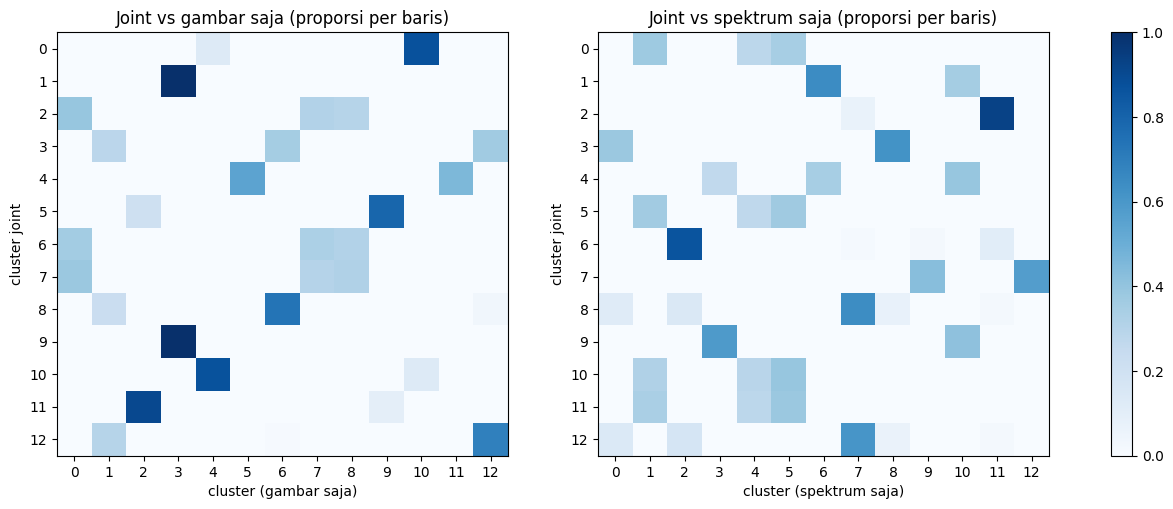

In [ ]:
LAB_KM = {k: KMeans(K, n_init=10, random_state=SEED).fit_predict(v) for k, v in Z.items()}
r_ = np.random.default_rng(0); si = r_.choice(N, 8000, replace=False)
rows = {}
for k, v in Z.items():
    lab = LAB_KM[k]
    rows[k] = {'silhouette': silhouette_score(v[si], lab[si]), 'davies_bouldin': davies_bouldin_score(v, lab),
               'stabilitas': stability(v, K), 'NMI mikroskop (rendah=baik)': NMI(lab, MIC),
               'ARI vs joint': ARI(lab, LAB_KM[FINAL_EMB])}
mod_df = pd.DataFrame(rows).T
display(mod_df.style.format('{:.3f}'))
mod_df.to_csv(f'{OUT_DIR}/perbandingan_modalitas.csv')

def merged_pairs(lab_ref, lab_other, thr=0.6):
    ct = pd.crosstab(lab_ref, lab_other, normalize='index')
    dom = ct.idxmax(1); share = ct.max(1)
    pairs = []
    for c in dom.unique():
        mem = [i for i in dom.index if dom[i] == c and share[i] >= thr]
        if len(mem) > 1: pairs.append(mem)
    return ct, pairs

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for a, k in zip(ax, ['gambar saja', 'spektrum saja']):
    ct, pairs = merged_pairs(LAB_KM[FINAL_EMB], LAB_KM[k])
    im = a.imshow(ct.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    a.set_xlabel(f'cluster ({k})'); a.set_ylabel('cluster joint'); a.set_yticks(range(ct.shape[0])); a.set_xticks(range(ct.shape[1]))
    a.set_title(f'Joint vs {k} (proporsi per baris)')
    print(f'Cluster joint yang DIGABUNG bila hanya {k}: {pairs if pairs else "tidak ada"}')
plt.colorbar(im, ax=ax); plt.show()

In [ ]:
def run_dec(Zx, k, seed=0, latent=16, pre_epochs=40, max_iter=40, tol=1e-3, gamma=0.1, bs=512, verbose=False):
    set_seed(seed)
    X = torch.tensor(Zx, device=DEVICE)
    d = X.shape[1]
    enc = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, latent)).to(DEVICE)
    dec = nn.Sequential(nn.Linear(latent, 128), nn.ReLU(), nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, d)).to(DEVICE)
    params = list(enc.parameters()) + list(dec.parameters())
    opt = torch.optim.Adam(params, 1e-3)
    gen = torch.Generator().manual_seed(seed)
    for ep in range(pre_epochs):
        perm = torch.randperm(len(X), generator=gen).to(DEVICE)
        for i in range(0, len(X), bs):
            xb = X[perm[i:i + bs]]
            loss = F.mse_loss(dec(enc(xb)), xb); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad(): L = enc(X).cpu().numpy()
    km = KMeans(k, n_init=10, random_state=seed).fit(L)
    mu = nn.Parameter(torch.tensor(km.cluster_centers_, device=DEVICE, dtype=torch.float32))
    opt = torch.optim.Adam(params + [mu], 1e-4)
    def soft(z):
        q = 1.0 / (1.0 + ((z[:, None, :] - mu[None]) ** 2).sum(-1))
        return q / q.sum(1, keepdim=True)
    y_prev = km.labels_
    for it in range(max_iter):
        with torch.no_grad():
            q = soft(enc(X)); p = q ** 2 / q.sum(0); p = p / p.sum(1, keepdim=True)
        y = q.argmax(1).cpu().numpy(); delta = (y != y_prev).mean(); y_prev = y
        if verbose: print(f'    DEC iter {it}: perubahan label {delta:.4%}')
        if it > 0 and delta < tol: break
        perm = torch.randperm(len(X), generator=gen).to(DEVICE)
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]; z = enc(X[idx])
            loss = F.kl_div(soft(z).log(), p[idx], reduction='batchmean') + gamma * F.mse_loss(dec(z), X[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad(): y = soft(enc(X)).argmax(1).cpu().numpy()
    return y, it + 1

Zf = Z[FINAL_EMB]
METHODS = {
    'K-Means': lambda s: KMeans(K, n_init=10, random_state=s).fit_predict(Zf),
    'GMM':     lambda s: GaussianMixture(K, covariance_type='full', random_state=s, max_iter=300, reg_covar=1e-4).fit(Zf).predict(Zf),
    'DEC':     lambda s: run_dec(Zf, K, seed=s)[0],
}
LAB, rows = {}, {}
for nm, fn in METHODS.items():
    t0 = time.time()
    l0, l1 = fn(0), fn(1)
    LAB[nm] = l0
    sizes = np.bincount(l0, minlength=K)
    rows[nm] = {'silhouette': silhouette_score(Zf[si], l0[si]), 'davies_bouldin': davies_bouldin_score(Zf, l0),
                'stabilitas antar-seed (ARI)': ARI(l0, l1), 'NMI mikroskop': NMI(l0, MIC),
                'cluster terkecil': int(sizes.min()), 'cluster terbesar': int(sizes.max()), 'waktu (s)': time.time() - t0}
    print(f'{nm} selesai ({time.time()-t0:.0f}s)')
meth_df = pd.DataFrame(rows).T
display(meth_df.style.format('{:.3f}', subset=['silhouette', 'davies_bouldin', 'stabilitas antar-seed (ARI)', 'NMI mikroskop']))
print('ARI antar metode:')
display(pd.DataFrame({a: {b: ARI(LAB[a], LAB[b]) for b in LAB} for a in LAB}).round(3))

rank = (meth_df['silhouette'].rank(ascending=False) + meth_df['davies_bouldin'].rank()
        + meth_df['stabilitas antar-seed (ARI)'].rank(ascending=False))
FINAL_METHOD = rank.idxmin()
LABELS = LAB[FINAL_METHOD]
print('Metode akhir:', FINAL_METHOD, '| ukuran cluster:', np.bincount(LABELS).tolist())

K-Means selesai (4s)
GMM selesai (23s)
DEC selesai (29s)


,silhouette,davies_bouldin,stabilitas antar-seed (ARI),NMI mikroskop,cluster terkecil,cluster terbesar,waktu (s)
K-Means,0.170,2.269,0.744,0.000,1985.000000,3911.000000,3.804867
GMM,0.158,2.745,0.743,0.000,1651.000000,4979.000000,23.328802
DEC,0.162,2.335,0.777,0.000,1883.000000,3682.000000,28.890814


ARI antar metode:


,K-Means,GMM,DEC
K-Means,1.000,0.661,0.820
GMM,0.661,1.000,0.681
DEC,0.820,0.681,1.000


Metode akhir: K-Means | ukuran cluster: [2011, 2677, 1985, 2736, 3656, 3911, 3131, 2024, 3543, 3455, 2310, 2318, 2243]


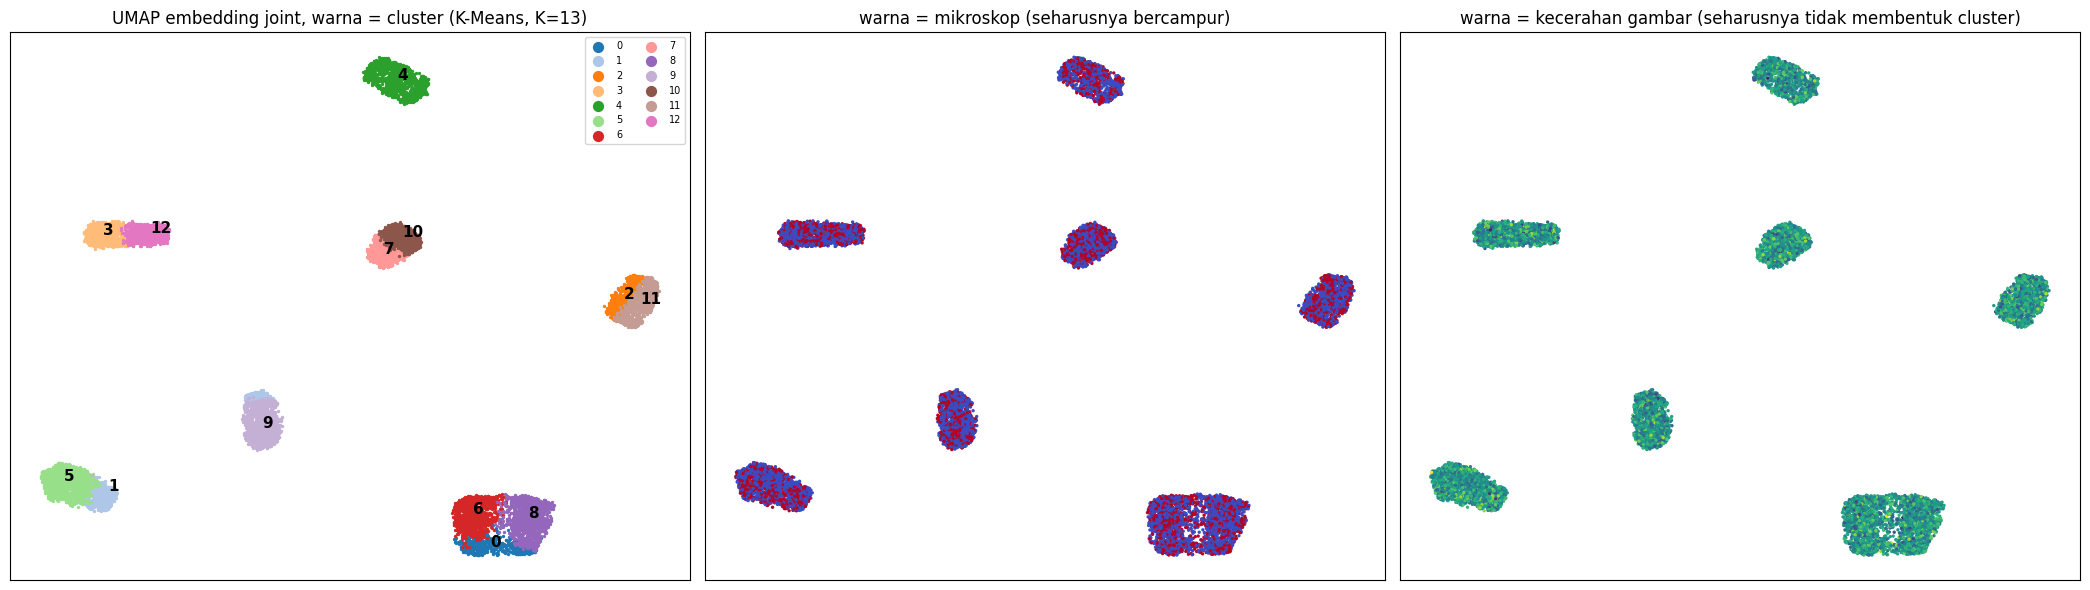

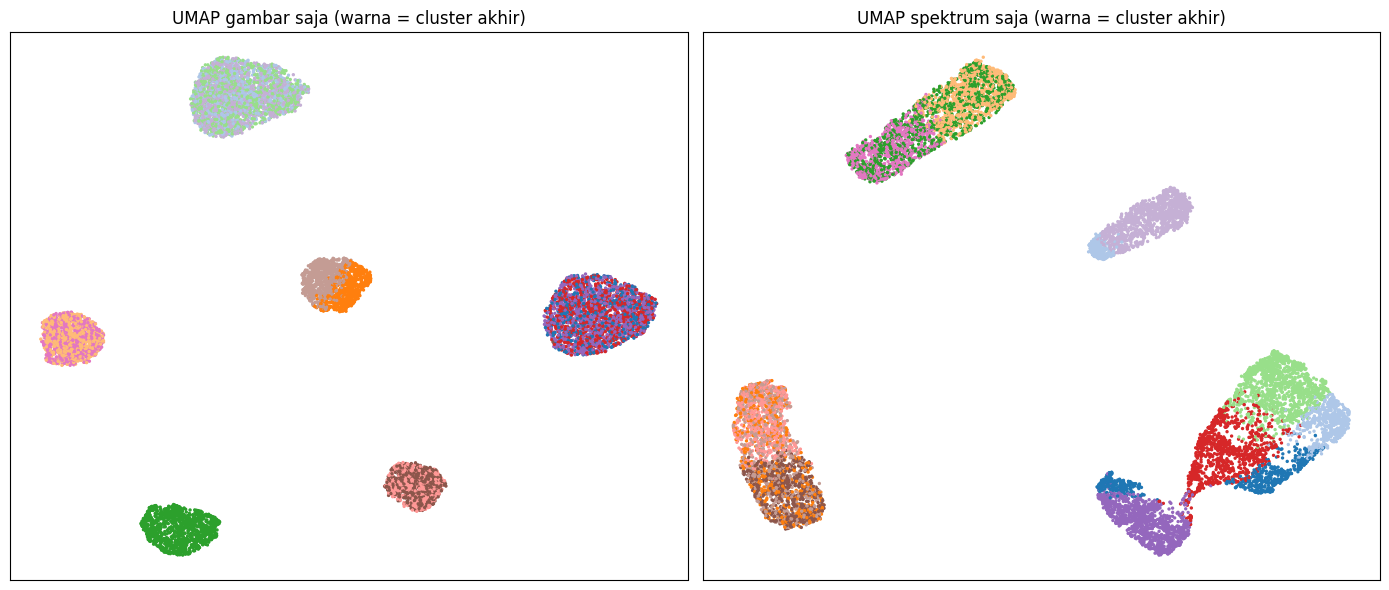

In [ ]:
try:
    import umap
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'umap-learn'], check=False)
    try:
        import umap
    except ImportError:
        umap = None

vi = np.random.default_rng(1).choice(N, 12000, replace=False)
if umap is not None:
    U = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(Zf[vi]); vname = 'UMAP'
else:
    from sklearn.manifold import TSNE
    U = TSNE(2, perplexity=40, init='pca', random_state=SEED).fit_transform(Zf[vi]); vname = 't-SNE'

fig, ax = plt.subplots(1, 3, figsize=(21, 6))
cm = plt.get_cmap('tab20')
for c in range(K):
    m = LABELS[vi] == c
    ax[0].scatter(U[m, 0], U[m, 1], s=2, color=cm(c % 20), label=str(c))
    ax[0].text(*np.median(U[m], 0), str(c), fontsize=11, weight='bold')
ax[0].set_title(f'{vname} embedding joint, warna = cluster ({FINAL_METHOD}, K={K})'); ax[0].legend(markerscale=5, fontsize=7, ncol=2)
ax[1].scatter(U[:, 0], U[:, 1], s=2, c=MIC[vi], cmap='coolwarm'); ax[1].set_title('warna = mikroskop (seharusnya bercampur)')
ax[2].scatter(U[:, 0], U[:, 1], s=2, c=img_mean[vi], cmap='viridis'); ax[2].set_title('warna = kecerahan gambar (seharusnya tidak membentuk cluster)')
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, k in zip(ax, ['gambar saja', 'spektrum saja']):
    Uk = (umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(Z[k][vi]) if umap is not None
          else TSNE(2, perplexity=40, init='pca', random_state=SEED).fit_transform(Z[k][vi]))
    a.scatter(Uk[:, 0], Uk[:, 1], s=2, c=[cm(c % 20) for c in LABELS[vi]]); a.set_title(f'{vname} {k} (warna = cluster akhir)'); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

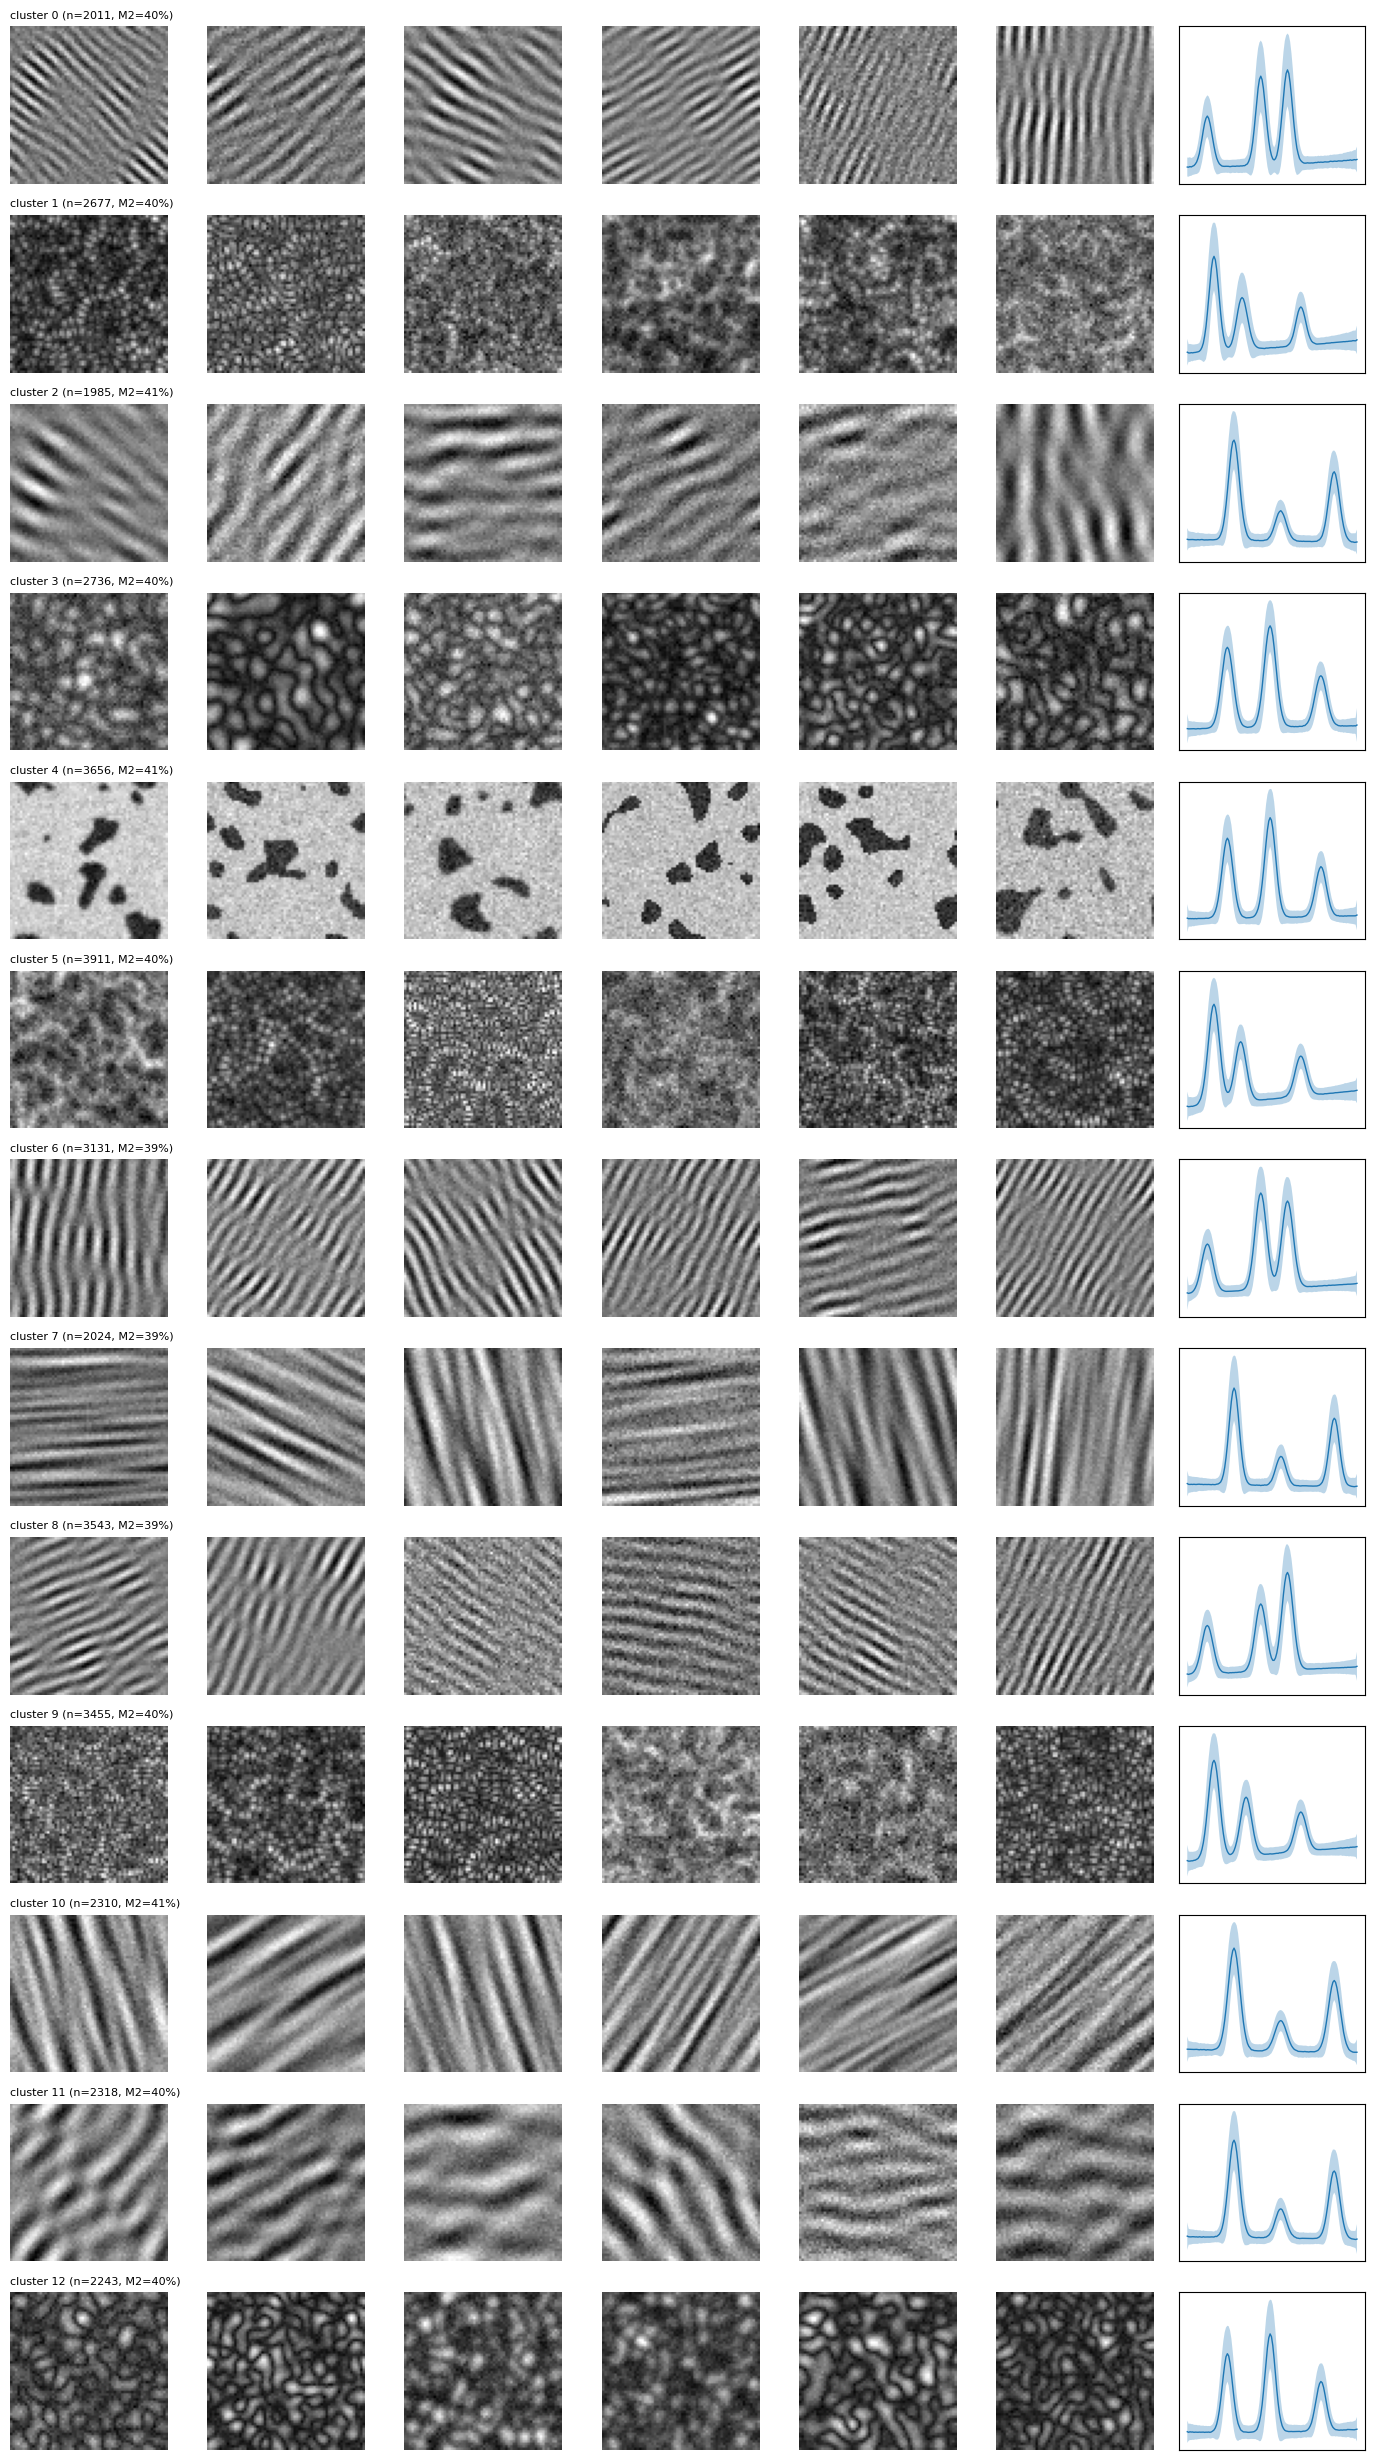

In [ ]:
# contoh tiap cluster: gambar + spektrum rata-rata
n_show = 6
fig, ax = plt.subplots(K, n_show + 1, figsize=(2 * (n_show + 1), 1.9 * K))
for c in range(K):
    mem = np.where(LABELS == c)[0]
    for j, k in enumerate(np.random.default_rng(c).choice(mem, min(n_show, len(mem)), replace=False)):
        ax[c, j].imshow(IMG[k], cmap='gray'); ax[c, j].axis('off')
    mu_s, sd_s = SPEC[mem].mean(0), SPEC[mem].std(0)
    ax[c, -1].plot(mu_s, lw=1); ax[c, -1].fill_between(range(128), mu_s - sd_s, mu_s + sd_s, alpha=.3); ax[c, -1].set_xticks([]); ax[c, -1].set_yticks([])
    ax[c, 0].set_title(f'cluster {c} (n={len(mem)}, M2={MIC[mem].mean():.0%})', fontsize=8, loc='left')
plt.tight_layout(); plt.show()

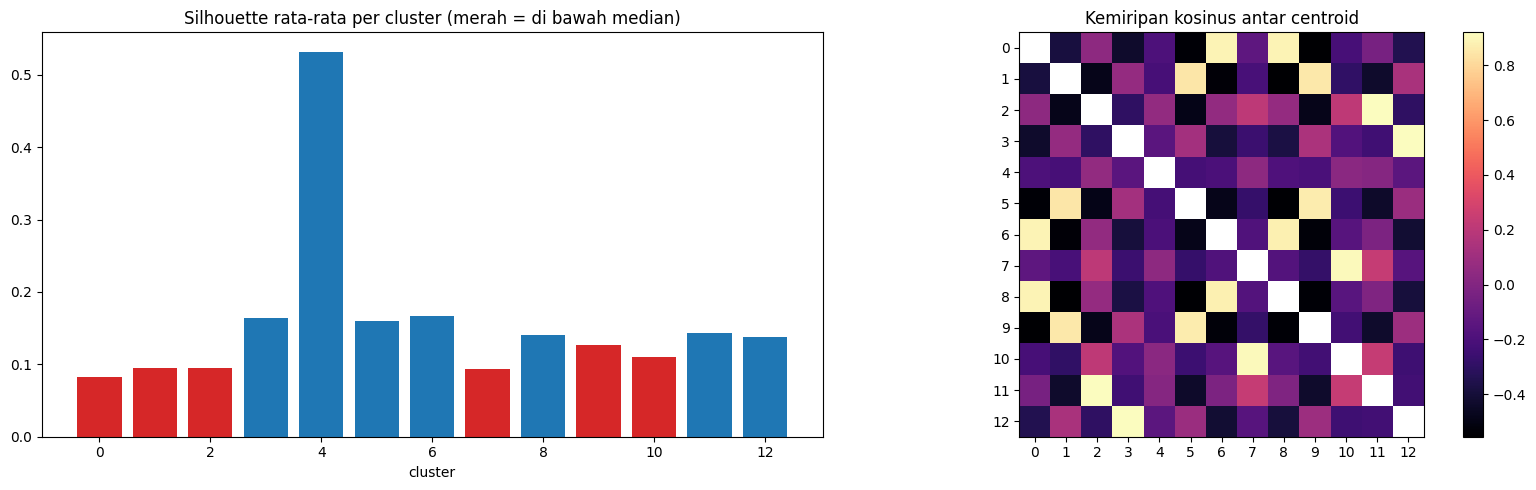

,cluster A,cluster B,kemiripan centroid,dipisahkan oleh gambar-saja? (ARI),dipisahkan oleh spektrum-saja? (ARI)
0,2,11,0.920,0.554,0.002
1,3,12,0.920,0.000,0.381
2,7,10,0.903,0.000,0.393
3,0,8,0.888,-0.001,0.444
4,0,6,0.886,-0.001,0.652


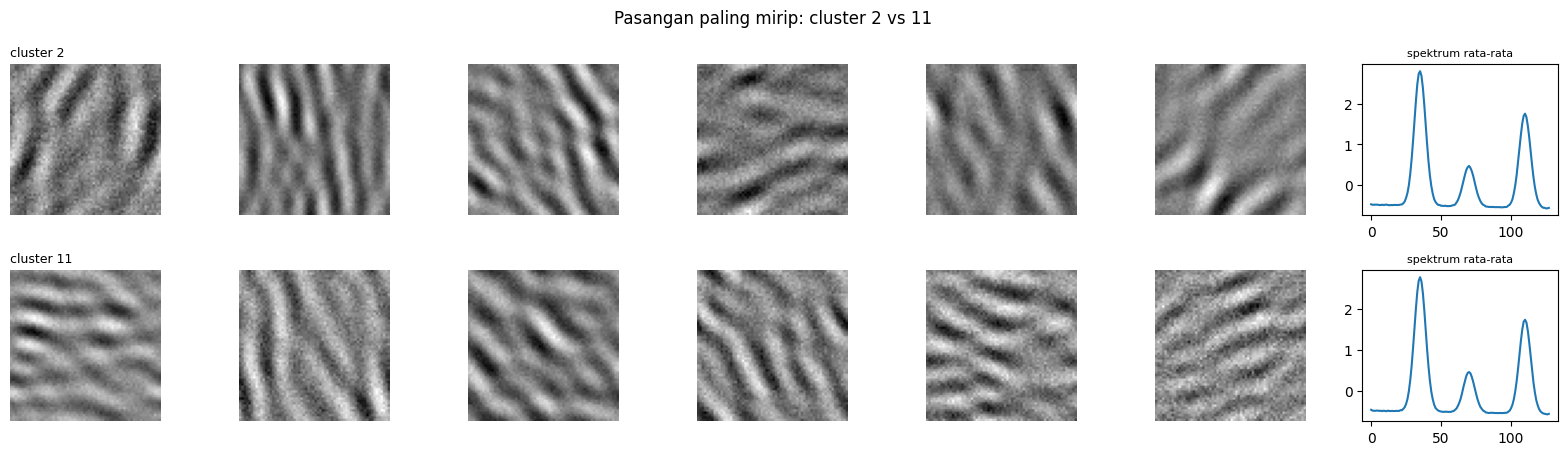

In [ ]:
# cluster yang sulit dipisahkan: silhouette per cluster + kemiripan centroid
sil_s = silhouette_samples(Zf[si], LABELS[si])
sil_c = pd.Series(sil_s).groupby(LABELS[si]).mean()
cent = np.stack([Zf[LABELS == c].mean(0) for c in range(K)])
cn = cent / np.linalg.norm(cent, axis=1, keepdims=True)
S = cn @ cn.T; np.fill_diagonal(S, np.nan)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].bar(sil_c.index, sil_c.values, color=['tab:red' if v < sil_c.median() else 'tab:blue' for v in sil_c.values])
ax[0].set_title('Silhouette rata-rata per cluster (merah = di bawah median)'); ax[0].set_xlabel('cluster')
im = ax[1].imshow(S, cmap='magma', vmin=np.nanmin(S), vmax=np.nanmax(S)); ax[1].set_title('Kemiripan kosinus antar centroid')
ax[1].set_xticks(range(K)); ax[1].set_yticks(range(K)); plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

iu = np.triu_indices(K, 1)
pairs = sorted(zip(S[iu], iu[0], iu[1]), reverse=True)[:5]
hard = []
for s, a, b in pairs:
    hard.append({'cluster A': a, 'cluster B': b, 'kemiripan centroid': round(float(s), 3),
                 'dipisahkan oleh gambar-saja? (ARI)': round(ARI(LAB_KM['gambar saja'][np.isin(LABELS, [a, b])], LABELS[np.isin(LABELS, [a, b])]), 3),
                 'dipisahkan oleh spektrum-saja? (ARI)': round(ARI(LAB_KM['spektrum saja'][np.isin(LABELS, [a, b])], LABELS[np.isin(LABELS, [a, b])]), 3)})
display(pd.DataFrame(hard))

s, a, b = pairs[0]
fig, ax = plt.subplots(2, 7, figsize=(16, 4.6))
for r, c in enumerate([a, b]):
    mem = np.where(LABELS == c)[0]
    for j, k in enumerate(np.random.default_rng(7).choice(mem, min(6, len(mem)), replace=False)):
        ax[r, j].imshow(IMG[k], cmap='gray'); ax[r, j].axis('off')
    ax[r, 0].set_title(f'cluster {c}', loc='left', fontsize=9)
    ax[r, 6].plot(SPEC[mem].mean(0)); ax[r, 6].set_title('spektrum rata-rata', fontsize=8)
plt.suptitle(f'Pasangan paling mirip: cluster {a} vs {b}'); plt.tight_layout(); plt.show()

In [ ]:
out = pd.DataFrame({'id_sampel': meta['id_sampel'].values, 'cluster': LABELS.astype(int)})
assert len(out) == N and out['id_sampel'].is_unique and out['cluster'].dtype.kind == 'i'
out.to_csv(f'{OUT_DIR}/cluster.csv', index=False)
json.dump({'K': K, 'best_k_per_criterion': best_k, 'embedding': FINAL_EMB, 'method': FINAL_METHOD, 'cfg': CFG,
           'pca_dim': PCA_DIM, 'seed': SEED}, open(f'{OUT_DIR}/cluster_config.json', 'w'), indent=2)
print(out.head()); print('ukuran cluster:', out.cluster.value_counts().sort_index().to_dict())
try:
    files.download(f'{OUT_DIR}/cluster.csv')
except Exception as e:
    print('Unduh manual dari panel Files:', e)

  id_sampel  cluster
0   S966119       10
1   S315633        8
2   S805122        9
3   S467543        6
4   S475842        6
ukuran cluster: {0: 2011, 1: 2677, 2: 1985, 3: 2736, 4: 3656, 5: 3911, 6: 3131, 7: 2024, 8: 3543, 9: 3455, 10: 2310, 11: 2318, 12: 2243}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>